# Panoramik Röntgenden Dental Yaş Tahmini: Beş CNN Modelinin Karşılaştırılması

TÜBİTAK 2209-A ön çalışması, 1. kısım · Hazırlayan: Nurullah Barış Çelik · Danışman: Prof. Dr. Selami Beyhan

Amaç: Panoramik diş röntgeninden kişinin yaşını tahmin etmek ve ConvNeXt-Tiny, Xception, DenseNet-121, EfficientNet-B0 ile ResNet-50 modellerini aynı koşullarda karşılaştırmak.

## Sonuçların özeti

| Sıra | Model | MAE (yıl) | %95 güven aralığı | R² | ±2 yıl içinde | Parametre |
|---|---|---|---|---|---|---|
| 1 | ConvNeXt-Tiny | 1,06 | 0,96–1,16 | 0,68 | %85,0 | 27,8 M |
| 2 | ResNet-50 | 1,11 | 1,01–1,21 | 0,67 | %85,4 | 23,5 M |
| 3 | EfficientNet-B0 | 1,14 | 1,04–1,24 | 0,65 | %84,7 | 4,0 M |
| 4 | Xception | 1,20 | 1,10–1,32 | 0,61 | %79,9 | 20,8 M |
| 5 | DenseNet-121 | 1,20 | 1,11–1,30 | 0,63 | %83,7 | 7,0 M |
| – | *Taban çizgisi (tüm görüntüler için ortanca yaş)* | *2,04* | | *−0,15* | *%69,7* | |

- Beş modelin tamamı, taban çizgisinin hatasını yaklaşık yarıya indirmektedir.
- En düşük hata ConvNeXt-Tiny ile elde edilmiştir; ancak beş modeli birlikte sınayan Friedman testi anlamlı bulunmamıştır (p = 0,084). Bu nedenle modeller arasında kesin bir sıralama yapılamamaktadır.
- Sonuçlar, şu an erişilebilen açık erişimli Zenodo veri setinde (temizlik sonrası 294 görüntü, 9-19 yaş) elde edilmiştir ve ön sonuç niteliğindedir.

## 1. Veri setinin seçimi

Veri seti seçiminde görüntü sayısı, yaş aralığı, yaş etiketi ve erişim durumu dikkate alınmıştır. İncelenen beş kaynak aşağıda verilmiştir:

| Veri seti | Görüntü | Yaş aralığı | Yaş etiketi | Erişim |
|---|---|---|---|---|
| UFPE Brezilya (Sci. Reports 2024) | 12.827 (10.036 hasta) | 2,25–96,5 | Var | E-posta ile talep: kurumsal adresten, koşullar kabul edilerek |
| Tufts Dental Database | 1.000 | Belirtilmemiş | Kaynaklarda bulunamadı (indirme dosyaları incelenemedi) | Sitede indirme bilgisi bulunamadı |
| Zenodo 16745408 | 296 | 9–19 | Var (tam sayı yaş, dosya adında) | Açık (CC BY 4.0) |
| Dental_011 | 295 | 9–19 | Var | Zenodo setiyle aynı veri |
| Kaggle OPG Across Ages | 24 | 3–64 | Var | Açık erişimli, örneklem çok küçük |

Sonuç:

- En fazla görüntüye ve en geniş yaş aralığına sahip veri seti UFPE'dir; ancak bu veri setine erişim talep ve onay gerektirmektedir.
- Tufts veri setinin kaynaklarında yaş etiketi bulunamadığından bu çalışmada kullanılamamıştır.
- Bu nedenle çalışma, şu an erişilebilen ve yaş etiketi bulunan en büyük veri seti olan Zenodo 16745408 üzerinde yürütülmüştür.
- Kod veri setine bağlı değildir; UFPE verisine erişildiğinde yalnızca veri yükleme hücresinin değiştirilmesi yeterlidir.
- Yaş aralığı dar olduğu için buradaki hatalar, geniş yaş aralıklı çalışmalarla doğrudan karşılaştırılamaz.

## 2. Kurulum

Kullanılan kütüphaneler: PyTorch (model eğitimi), timm (hazır modeller), scikit-learn (veri bölme ve ölçütler).

Rastgelelik sabitlenir (`SEED = 42`), böylece her model aynı veri bölünmelerini görür. Apple GPU (MPS) tamamen deterministik olmadığı için tekrar çalıştırmada sonuçlar küçük farklar gösterebilir.

In [1]:
import os, re, json, time, hashlib, gc, warnings
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, timm
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import r2_score
from scipy import stats

DRY = os.environ.get('DENTAL_DRY') == '1'   # hızlı deneme modu: tam sonuç üretmez
SEED = 42
IMG_SIZE = 224
BATCH = 16
MAX_EPOCHS = 1 if DRY else 40
PATIENCE = 8
LR = 1e-4
WEIGHT_DECAY = 1e-2
N_FOLDS = 5
RUN_FOLDS = 1 if DRY else N_FOLDS
DATA_DIR = Path('data/zenodo_16745408/extracted/dataset ++')
RESULTS = Path('results_dry' if DRY else 'results'); RESULTS.mkdir(exist_ok=True)
DEVICE = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')

COLORS = {'ConvNeXt-Tiny':'#2a78d6','Xception':'#eb6834','DenseNet-121':'#1baf7a','EfficientNet-B0':'#eda100','ResNet-50':'#e87ba4'}
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
                     'grid.color':'#e6e5e1','grid.linewidth':.6,'axes.axisbelow':True,'font.size':10})
print('Cihaz:', DEVICE, '| torch', torch.__version__, '| timm', timm.__version__, '| deneme modu:', DRY)

Cihaz: mps | torch 2.15.0 | timm 1.0.30 | deneme modu: False


## 3. Veriyi tanıma

Yaş bilgisi dosya adının başındaki sayıdır: `14 25.jpg` → 14 yaş.

Bu bölümde görüntü sayısı, yaş dağılımı, görüntü boyutları ve örnek görüntüler incelenmektedir.

Toplam görüntü: 296
Yaş aralığı   : 9 - 19 | ortalama 15.04 | ortanca 16.0
Düşük çözünürlüklü (genişlik 400 px): 287 | yüksek çözünürlüklü: 9


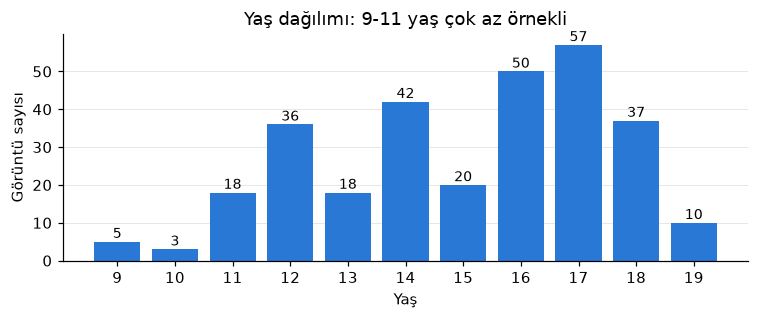

In [2]:
rows = []
for p in sorted(DATA_DIR.glob('*.jpg')):
    im = Image.open(p)
    rows.append(dict(path=str(p), name=p.name, age=int(re.match(r'\d+', p.name).group()),
                     w=im.size[0], h=im.size[1], mode=im.mode,
                     md5=hashlib.md5(p.read_bytes()).hexdigest()))
df_all = pd.DataFrame(rows)
print('Toplam görüntü:', len(df_all))
print('Yaş aralığı   :', df_all.age.min(), '-', df_all.age.max(), '| ortalama', round(df_all.age.mean(),2), '| ortanca', df_all.age.median())
print('Düşük çözünürlüklü (genişlik 400 px):', (df_all.w==400).sum(), '| yüksek çözünürlüklü:', (df_all.w>500).sum())

counts = df_all.age.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7,3))
ax.bar(counts.index, counts.values, color='#2a78d6', width=.8)
for x,y in counts.items(): ax.text(x, y+1, y, ha='center', fontsize=9)
ax.set(xlabel='Yaş', ylabel='Görüntü sayısı', title='Yaş dağılımı: 9-11 yaş çok az örnekli', xticks=counts.index); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

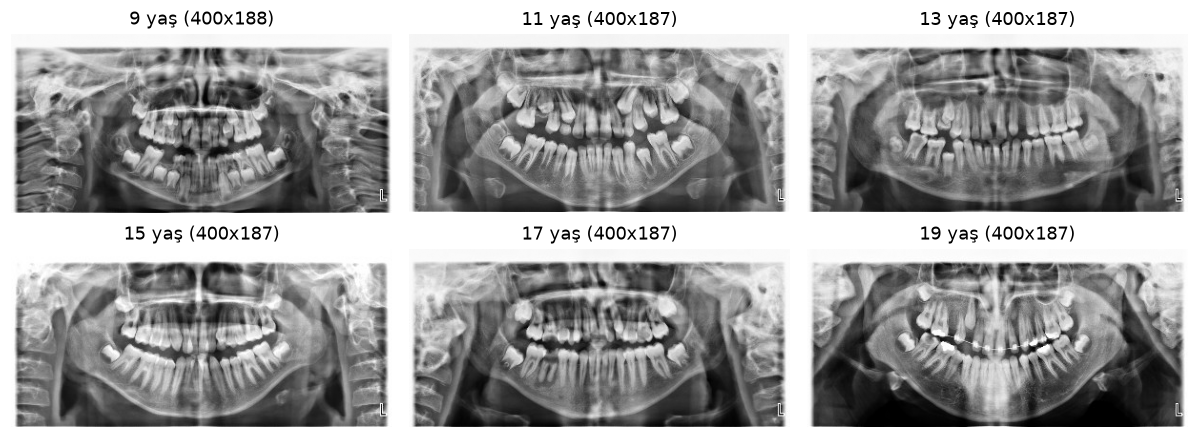

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(11,4.2))
for ax, a in zip(axes.ravel(), [9, 11, 13, 15, 17, 19]):
    r = df_all[df_all.age==a].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(r.path).convert('L'), cmap='gray'); ax.set_title(f'{a} yaş ({r.w}x{r.h})'); ax.axis('off')
plt.tight_layout(); plt.show()

Gözlemler:

- Küçük yaşlarda süt dişleri ve gelişmekte olan kökler, büyük yaşlarda ise tamamlanmış kökler ve yirmi yaş dişleri görülmektedir.
- Görüntülerin büyük kısmı yaklaşık 400×187 piksel boyutundadır. Bu çözünürlükte kök ucu gibi ince ayrıntılar kaybolabilir.
- 9-11 yaş grubunda toplam 26 görüntü var; bu yaşlardaki sonuçlar daha az güvenilirdir.

## 4. Veri temizliği: tekrar eden görüntüler

Aynı görüntünün hem eğitim hem test kümesinde bulunmaması için tekrar eden görüntüler kontrol edilmiştir.

İki kontrol uygulanmıştır:

1. Birebir kopyalar: İçeriği aynı olan dosyalardan biri çıkarılır.
2. Çok benzeyen görüntüler: Küçültülmüş görüntüler arasındaki korelasyon 0,90'ın üzerindeyse, aynı kişi olabilecekleri için aynı gruba konur. Aynı gruptaki görüntüler hiçbir zaman eğitim ve teste ayrı düşmez.

Veri setinde hasta numarası bulunmamaktadır. Aynı kişinin farklı yıllarda çekilmiş röntgenleri varsa bunlar kesin olarak ayıklanamamaktadır.

In [4]:
dups = df_all[df_all.duplicated('md5', keep=False)].groupby('md5').name.apply(list).tolist()
print('Birebir kopyalar:', dups)
df = df_all.drop_duplicates('md5').reset_index(drop=True)

X = np.stack([np.asarray(Image.open(p).convert('L').resize((96,48), Image.BICUBIC), float).ravel() for p in df.path])
Z = (X - X.mean(1, keepdims=True)) / X.std(1, keepdims=True)
C = Z @ Z.T / Z.shape[1]
group = np.arange(len(df))
pairs = [(i,j) for i in range(len(df)) for j in range(i+1,len(df)) if C[i,j] > .90]
for i,j in pairs:
    print(f'Çok benzer çift: {df.name[i]} | {df.name[j]} | korelasyon {C[i,j]:.3f}')
    group[group==group[j]] = group[i]
df['group'] = group
print('Görüntü:', len(df), '| bağımsız grup:', df.group.nunique())
print('Tipik çift korelasyonu (ortanca):', round(float(np.median(C[np.triu_indices(len(df),1)])),3))

Birebir kopyalar: [['11 16.jpg', '11 17.jpg'], ['17  1.jpg', '17 3.jpg']]


Çok benzer çift: 12 3.jpg | 12 33.jpg | korelasyon 0.913
Görüntü: 294 | bağımsız grup: 293
Tipik çift korelasyonu (ortanca): 0.695


## 5. Ortak deney protokolü

Beş modelde de aynı deney ayarları kullanılmıştır.

45 görüntülük tek bir test kümesinde sonuç, seçilen görüntülere çok bağlı olacağından 5 katlı çapraz doğrulama kullanılmıştır. Her görüntü, eğitimde görmemiş bir model tarafından tahmin edilmiştir.

| Ayar | Değer | Neden |
|---|---|---|
| Bölme | 5 kat, yaş bandına göre dengeli, gruplar ayrılmadan | Her katta benzer yaş dağılımı, sızıntı yok |
| Doğrulama | Eğitim kısmının yaklaşık %14'ü | Erken durdurma test verisine bakmadan yapılır |
| Girdi | 224×224, gri tonlama 3 kanala kopyalı | Tüm modellerde aynı boyut |
| Başlangıç ağırlıkları | ImageNet | Az veride sıfırdan eğitmekten daha iyi başlangıç |
| Çıktı | Tek sayı (yaş) | Bu bir regresyon problemi |
| Kayıp | L1 (ortalama mutlak hata) | Rapor edilen ölçütle aynı |
| Optimizasyon | AdamW, öğrenme hızı 1e-4, kosinüs azaltma | Her model için aynı |
| Eğitim | En fazla 40 tur, 8 tur iyileşme yoksa dur | Ezberlemeyi sınırlar |
| Veri çoğaltma | ±5° döndürme, %3 kaydırma, ±%5 ölçek, ±%15 parlaklık/kontrast | Çekim farklarını taklit eder |
| Yatay çevirme | Yok | Sol-sağ simetri 2. aşamanın konusu |

Xception normalde 299×299 ile kullanılır. Ortak protokol gereği burada 224×224 kullanıldı; giriş çözünürlüğünün etkisi projenin sonraki aşamasında ölçülecek.

In [5]:
bands = pd.cut(df.age, [8,11,13,15,16,17,19], labels=['9-11','12-13','14-15','16','17','18-19'])
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits = []
for fold, (trval, te) in enumerate(sgkf.split(df, bands, df.group)):
    inner = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED+fold)
    tr_i, va_i = next(inner.split(df.iloc[trval], bands.iloc[trval], df.group.iloc[trval]))
    tr, va = trval[tr_i], trval[va_i]
    assert not (set(df.group[tr]) & set(df.group[te])) and not (set(df.group[tr]) & set(df.group[va]))
    splits.append((tr, va, te))
    print(f'Kat {fold+1}: eğitim {len(tr)} | doğrulama {len(va)} | test {len(te)} | test yaş ort. {df.age[te].mean():.2f}')
print('Gruplar ayrılmadı: eğitim ve test kesişimi boş.')

def load(p):
    return torch.from_numpy(np.asarray(Image.open(p).convert('L').resize((IMG_SIZE,IMG_SIZE), Image.BICUBIC), dtype=np.uint8).copy()).unsqueeze(0).repeat(3,1,1)
IMAGES = torch.stack([load(p) for p in df.path])
print('Bellekteki görüntüler:', tuple(IMAGES.shape))

Kat 1: eğitim 201 | doğrulama 34 | test 59 | test yaş ort. 14.95
Kat 2: eğitim 201 | doğrulama 34 | test 59 | test yaş ort. 15.05
Kat 3: eğitim 201 | doğrulama 34 | test 59 | test yaş ort. 15.08
Kat 4: eğitim 201 | doğrulama 34 | test 59 | test yaş ort. 15.07
Kat 5: eğitim 202 | doğrulama 34 | test 58 | test yaş ort. 15.09
Gruplar ayrılmadı: eğitim ve test kesişimi boş.


Bellekteki görüntüler: (294, 3, 224, 224)


## 6. Taban çizgisi

Modellerin başarısını değerlendirmek için en basit tahminci referans alınmıştır: görüntü kullanılmadan tüm örnekler için eğitim verisinin ortanca yaşının tahmin edilmesi. Modellerin bu değerden belirgin biçimde daha iyi sonuç vermesi beklenir.

Kullanılan ölçütler:

- MAE: Ortalama mutlak hata, yıl cinsinden. Temel ölçüttür; küçük olması daha iyidir.
- RMSE: Büyük hataları daha çok cezalandırır.
- R²: Yaş farklılıklarının ne kadarının açıklandığı. 1 mükemmel, 0 ortalama tahmin kadar.
- ±1 / ±2 yıl: Hatası bu sınırın içinde kalan görüntü oranı.
- Yanlılık: Ortalama fazla (+) veya az (−) tahmin eğilimi.

In [6]:
def metrics(y, p):
    e = p - y; a = np.abs(e)
    return dict(MAE=a.mean(), RMSE=np.sqrt((e**2).mean()), R2=r2_score(y,p), r=np.corrcoef(y,p)[0,1] if np.std(p)>0 else np.nan,
                within1=(a<=1).mean()*100, within2=(a<=2).mean()*100, bias=e.mean())

base = np.zeros(len(df))
for tr, va, te in splits: base[te] = np.median(df.age.values[np.r_[tr,va]])
base_m = metrics(df.age.values, base)
print('Taban çizgisi (ortanca tahmini):', {k: round(float(v),3) for k,v in base_m.items() if k!='r'})

Taban çizgisi (ortanca tahmini): {'MAE': 2.041, 'RMSE': 2.607, 'R2': -0.154, 'within1': 42.857, 'within2': 69.728, 'bias': 0.952}


## 7. Ortak eğitim kodu

Tek bir fonksiyon, beş modelin hepsini aynı şekilde eğitir:

1. Hazır modeli yükler, sınıflandırma katmanını tek sayı üreten bir katmanla değiştirir.
2. Her katta eğitir; doğrulama hatası en düşük turun ağırlıklarını saklar.
3. Test parçasını yalnızca en sonda bir kez tahmin eder.

Yaş, eğitim ortalaması ve standart sapmasıyla ölçeklenir; bilgi test verisinden alınmaz. Her katın sonucu `results/` klasörüne yazılır, böylece çalışma yarıda kesilirse baştan başlamak gerekmez.

In [7]:
class XrayDS(Dataset):
    def __init__(self, idx, mean, std, train):
        self.idx, self.train = idx, train
        aug = [v2.RandomAffine(degrees=5, translate=(.03,.03), scale=(.95,1.05), interpolation=v2.InterpolationMode.BILINEAR),
               v2.ColorJitter(brightness=.15, contrast=.15)] if train else []
        self.tf = v2.Compose(aug + [v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean, std)])
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.tf(IMAGES[j]), float(df.age.values[j])

@torch.no_grad()
def predict(model, loader, mu, sd):
    model.eval(); out = []
    for x,_ in loader: out.append(model(x.to(DEVICE)).squeeze(1).cpu())
    return torch.cat(out).numpy()*sd + mu

def train_fold(timm_name, fold):
    torch.manual_seed(SEED+fold); np.random.seed(SEED+fold)
    tr, va, te = splits[fold]
    model = timm.create_model(timm_name, pretrained=True, num_classes=1)
    if 'efficientnet' in timm_name:   # timm tek çıktılı son katmanı çok büyük başlatıyor; bkz. Bölüm 11
        head = model.get_classifier(); nn.init.trunc_normal_(head.weight, std=.01); nn.init.zeros_(head.bias)
    model = model.to(DEVICE)
    cfg = model.pretrained_cfg; mean, std = cfg['mean'], cfg['std']
    y = df.age.values; mu, sd = y[tr].mean(), y[tr].std()
    g = torch.Generator().manual_seed(SEED+fold)
    tr_dl = DataLoader(XrayDS(tr,mean,std,True), BATCH, shuffle=True, drop_last=True, generator=g)
    va_dl = DataLoader(XrayDS(va,mean,std,False), 32); te_dl = DataLoader(XrayDS(te,mean,std,False), 32)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, MAX_EPOCHS)
    best, best_state, wait, hist = 1e9, None, 0, []
    t0 = time.time()
    for ep in range(MAX_EPOCHS):
        model.train(); losses = []
        for xb, yb in tr_dl:
            xb = xb.to(DEVICE); yb = ((yb-mu)/sd).float().to(DEVICE)
            loss = nn.functional.l1_loss(model(xb).squeeze(1), yb)
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        sch.step()
        vmae = float(np.abs(predict(model, va_dl, mu, sd) - y[va]).mean())
        hist.append(dict(epoch=ep+1, train_mae=float(np.mean(losses))*sd, val_mae=vmae))
        if vmae < best:
            best, wait = vmae, 0
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state); model.to(DEVICE)
    pred = predict(model, te_dl, mu, sd)
    secs = time.time()-t0
    x = torch.zeros(1,3,IMG_SIZE,IMG_SIZE).to(DEVICE); model.eval(); t1 = time.time()
    with torch.no_grad():
        for _ in range(30): model(x)
    torch.mps.synchronize() if DEVICE=='mps' else None
    ms = (time.time()-t1)/30*1000
    params = sum(p.numel() for p in model.parameters())/1e6
    del model, best_state, opt; gc.collect(); torch.mps.empty_cache() if DEVICE=='mps' else None
    return pred, te, hist, dict(seconds=secs, ms_per_image=ms, params_m=params, best_val_mae=best, epochs=len(hist))

ALL = {}
def run_model(label, timm_name):
    oof = np.full(len(df), np.nan); hists = []; infos = []
    tag = timm_name.replace('.','_')
    for fold in range(RUN_FOLDS):
        f = RESULTS/f'{tag}_fold{fold}.json'
        if f.exists():
            s = json.loads(f.read_text()); pred, te, hist, info = np.array(s['pred']), np.array(s['te']), s['hist'], s['info']
        else:
            pred, te, hist, info = train_fold(timm_name, fold)
            f.write_text(json.dumps(dict(pred=pred.tolist(), te=np.asarray(te).tolist(), hist=hist, info=info)))
        oof[te] = pred; hists.append(hist); infos.append(info)
        print(f'Kat {fold+1}: test MAE {np.abs(pred-df.age.values[te]).mean():.3f} yıl | en iyi doğrulama {info["best_val_mae"]:.3f} | {info["epochs"]} tur | {info["seconds"]/60:.1f} dk')
    ok = ~np.isnan(oof); m = metrics(df.age.values[ok], oof[ok])
    ALL[label] = dict(oof=oof, hists=hists, infos=infos, metrics=m)
    print(f'\n{label}: MAE {m["MAE"]:.3f} | RMSE {m["RMSE"]:.3f} | R² {m["R2"]:.3f} | ±1 yıl %{m["within1"]:.1f} | ±2 yıl %{m["within2"]:.1f} | yanlılık {m["bias"]:+.3f}')
    fig, ax = plt.subplots(1, 2, figsize=(10,3.4))
    for k,h in enumerate(hists):
        ax[0].plot([r['epoch'] for r in h],[r['val_mae'] for r in h], color=COLORS[label], lw=1.6, alpha=.35+.13*k)
    ax[0].axhline(base_m['MAE'], color='#52514e', ls='--', lw=1); ax[0].text(.99, base_m['MAE'], 'taban çizgisi ', transform=ax[0].get_yaxis_transform(), ha='right', va='bottom', fontsize=9, color='#52514e')
    ax[0].set(xlabel='Tur', ylabel='Doğrulama MAE (yıl)', title=f'{label}: öğrenme eğrileri'); ax[0].set_ylim(top=base_m['MAE']*1.1)
    y = df.age.values[ok]; jit = np.random.default_rng(0).uniform(-.18,.18,ok.sum())
    ax[1].scatter(y+jit, oof[ok], s=16, color=COLORS[label], alpha=.6, linewidths=0); ax[1].plot([8.5,19.5],[8.5,19.5], color='#52514e', lw=1)
    ax[1].set(xlabel='Gerçek yaş', ylabel='Tahmin edilen yaş', title='Görülmemiş veride tahminler', xlim=(8.3,19.7), ylim=(8.3,19.7))
    plt.tight_layout(); plt.show()

## 8. ConvNeXt-Tiny

2022 tarihli bu model, klasik CNN yapısını Transformer modellerinden alınan fikirlerle (7×7 filtreler, farklı normalizasyon) günceller.

Kat 1: test MAE 0.962 yıl | en iyi doğrulama 0.952 | 40 tur | 9.3 dk
Kat 2: test MAE 1.165 yıl | en iyi doğrulama 1.020 | 25 tur | 5.6 dk
Kat 3: test MAE 1.143 yıl | en iyi doğrulama 0.717 | 15 tur | 3.3 dk
Kat 4: test MAE 0.993 yıl | en iyi doğrulama 0.888 | 22 tur | 5.0 dk
Kat 5: test MAE 1.041 yıl | en iyi doğrulama 1.150 | 36 tur | 7.8 dk

ConvNeXt-Tiny: MAE 1.061 | RMSE 1.362 | R² 0.685 | ±1 yıl %58.2 | ±2 yıl %85.0 | yanlılık +0.005


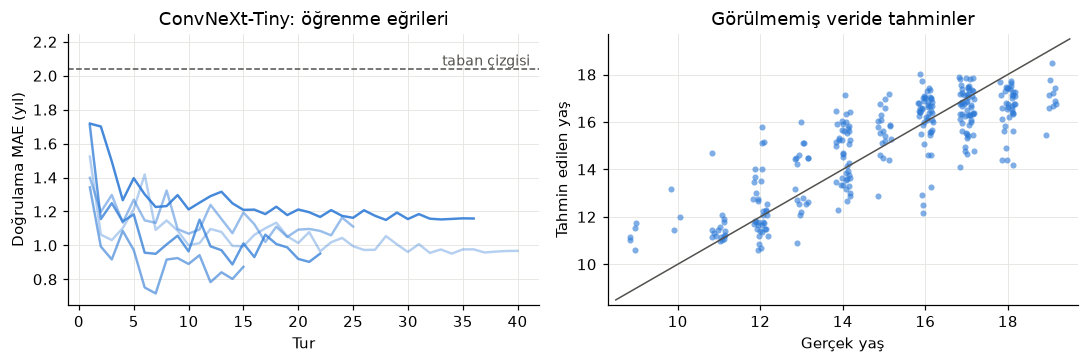

In [8]:
run_model('ConvNeXt-Tiny', 'convnext_tiny.fb_in1k')

## 9. Xception

Derinlemesine ayrılabilir evrişim kullanır: önce her kanal ayrı işlenir, sonra kanallar birleştirilir.

Kat 1: test MAE 1.155 yıl | en iyi doğrulama 1.076 | 27 tur | 10.4 dk
Kat 2: test MAE 1.424 yıl | en iyi doğrulama 1.046 | 13 tur | 1.8 dk
Kat 3: test MAE 1.167 yıl | en iyi doğrulama 0.909 | 16 tur | 2.9 dk
Kat 4: test MAE 1.156 yıl | en iyi doğrulama 1.026 | 13 tur | 2.5 dk
Kat 5: test MAE 1.113 yıl | en iyi doğrulama 1.315 | 13 tur | 2.6 dk

Xception: MAE 1.203 | RMSE 1.519 | R² 0.608 | ±1 yıl %51.7 | ±2 yıl %79.9 | yanlılık -0.093


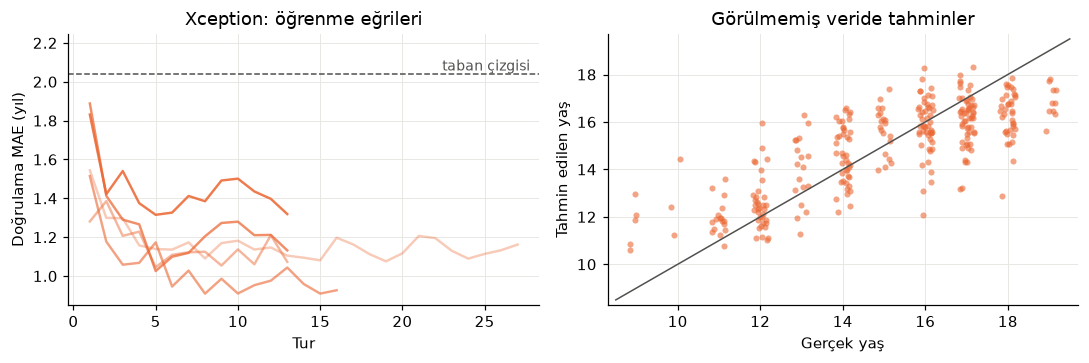

In [9]:
run_model('Xception', 'legacy_xception.tf_in1k')

## 10. DenseNet-121

Her katman, önceki tüm katmanların çıktısını girdi olarak alır. Bu yapı parametre sayısını düşürür.

Kat 1: test MAE 1.126 yıl | en iyi doğrulama 1.101 | 16 tur | 2.1 dk
Kat 2: test MAE 1.443 yıl | en iyi doğrulama 1.228 | 12 tur | 1.3 dk
Kat 3: test MAE 1.214 yıl | en iyi doğrulama 0.971 | 14 tur | 1.6 dk
Kat 4: test MAE 1.100 yıl | en iyi doğrulama 0.933 | 37 tur | 4.4 dk
Kat 5: test MAE 1.135 yıl | en iyi doğrulama 1.194 | 13 tur | 1.8 dk

DenseNet-121: MAE 1.204 | RMSE 1.483 | R² 0.626 | ±1 yıl %46.3 | ±2 yıl %83.7 | yanlılık -0.002


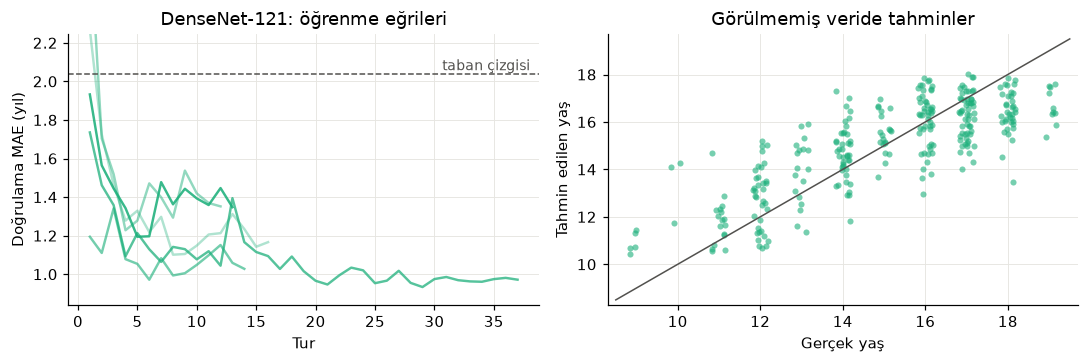

In [10]:
run_model('DenseNet-121', 'densenet121.tv_in1k')

## 11. EfficientNet-B0

Beş model arasında parametre sayısı en düşük olan modeldir. Derinlik, genişlik ve çözünürlüğü birlikte ölçekler.

İlk eğitimde bu modelin hatası 6,04 yıl çıktı; bu değer taban çizgisinden (2,04 yıl) daha kötüdür. Bunun sebebi kütüphanenin başlatma ayarıdır: timm, EfficientNet'in son katmanını çıktı sayısına göre başlatıyor ve tek çıktılı regresyonda ağırlıklar ±1 aralığına çıkıyor (diğer dört modelde standart sapma yaklaşık 0,01-0,02, burada 0,59). Bu yüzden yalnızca EfficientNet'in son katmanı, diğerleriyle aynı büyüklükte (standart sapma 0,01) başlatıldı ve yalnızca bu model yeniden eğitildi. Düzeltme test sonucuna bakılarak değil, başlangıç çıktılarının anormal büyük olması ölçülerek gerekçelendirildi. Hatalı ilk sonuçlar `results_effnet_bug/` klasöründe saklıdır.

Kat 1: test MAE 1.207 yıl | en iyi doğrulama 0.984 | 26 tur | 2.5 dk
Kat 2: test MAE 1.253 yıl | en iyi doğrulama 1.141 | 22 tur | 1.7 dk
Kat 3: test MAE 1.074 yıl | en iyi doğrulama 0.712 | 33 tur | 2.6 dk
Kat 4: test MAE 1.072 yıl | en iyi doğrulama 1.026 | 24 tur | 2.0 dk
Kat 5: test MAE 1.079 yıl | en iyi doğrulama 1.219 | 30 tur | 2.4 dk

EfficientNet-B0: MAE 1.137 | RMSE 1.439 | R² 0.648 | ±1 yıl %52.4 | ±2 yıl %84.7 | yanlılık -0.011


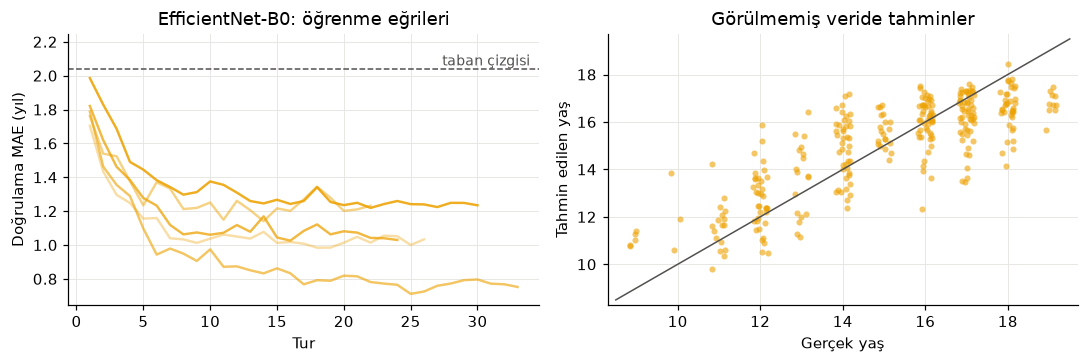

In [11]:
run_model('EfficientNet-B0', 'efficientnet_b0.ra_in1k')

## 12. ResNet-50

Tıbbi görüntülemede sık kullanılan bir referans modeldir. Atlamalı bağlantılar derin ağların eğitimini kolaylaştırır.

Kat 1: test MAE 1.093 yıl | en iyi doğrulama 0.911 | 23 tur | 2.5 dk
Kat 2: test MAE 1.290 yıl | en iyi doğrulama 1.009 | 15 tur | 1.6 dk
Kat 3: test MAE 1.019 yıl | en iyi doğrulama 1.034 | 20 tur | 2.4 dk
Kat 4: test MAE 1.029 yıl | en iyi doğrulama 1.063 | 19 tur | 2.3 dk
Kat 5: test MAE 1.115 yıl | en iyi doğrulama 1.127 | 14 tur | 1.7 dk

ResNet-50: MAE 1.109 | RMSE 1.394 | R² 0.670 | ±1 yıl %53.7 | ±2 yıl %85.4 | yanlılık +0.020


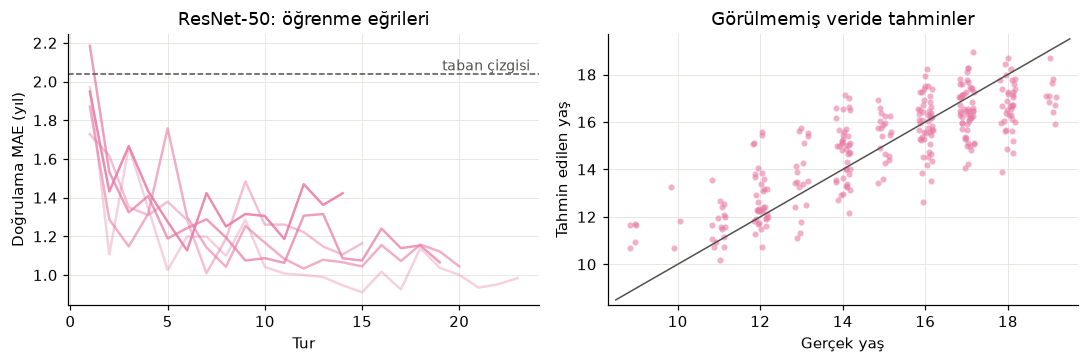

In [12]:
run_model('ResNet-50', 'resnet50.tv_in1k')

## 13. Sonuçların karşılaştırılması

Her model için tüm görüntülerin "görülmemiş veri" tahminlerinden ölçütler hesaplanır.

%95 güven aralığı bootstrap ile bulunur: görüntüler 5.000 kez rastgele yeniden seçilir ve MAE'nin ne kadar oynadığına bakılır.

In [13]:
def boot_ci(a, n=5000, seed=SEED):
    rng = np.random.default_rng(seed); s = [a[rng.integers(0,len(a),len(a))].mean() for _ in range(n)]
    return np.percentile(s,[2.5,97.5])
y = df.age.values; tbl = []
for k,v in ALL.items():
    ok = ~np.isnan(v['oof']); a = np.abs(v['oof'][ok]-y[ok]); lo,hi = boot_ci(a); m = v['metrics']
    fold_mae = [np.abs(v['oof'][splits[f][2]]-y[splits[f][2]]).mean() for f in range(RUN_FOLDS)]
    tbl.append({'Model':k,'MAE (yıl)':m['MAE'],'%95 GA alt':lo,'%95 GA üst':hi,'Kat std':np.std(fold_mae),'RMSE':m['RMSE'],'R²':m['R2'],'r':m['r'],
                '±1 yıl %':m['within1'],'±2 yıl %':m['within2'],'Yanlılık':m['bias'],'Param (M)':v['infos'][0]['params_m'],
                'Eğitim (dk/kat)':np.mean([i['seconds'] for i in v['infos']])/60,'Tahmin (ms/görüntü)':np.median([i['ms_per_image'] for i in v['infos']]),'Ort. tur':np.mean([i['epochs'] for i in v['infos']])})
res = pd.DataFrame(tbl).sort_values('MAE (yıl)').reset_index(drop=True)
res.to_csv(RESULTS/'comparison.csv', index=False)
print('Taban çizgisi MAE:', round(base_m['MAE'],3))
res.round(3)

Taban çizgisi MAE: 2.041


,Model,MAE (yıl),%95 GA alt,%95 GA üst,Kat std,RMSE,R²,r,±1 yıl %,±2 yıl %,Yanlılık,Param (M),Eğitim (dk/kat),Tahmin (ms/görüntü),Ort. tur
0,ConvNeXt-Tiny,1.061,0.963,1.165,0.080,1.362,0.685,0.828,58.163,85.034,0.005,27.821,6.186,11.001,27.6
1,ResNet-50,1.109,1.014,1.208,0.098,1.394,0.670,0.819,53.741,85.374,0.020,23.510,2.078,15.603,18.2
2,EfficientNet-B0,1.137,1.038,1.239,0.077,1.439,0.648,0.805,52.381,84.694,-0.011,4.009,2.241,9.950,27.0
3,Xception,1.203,1.100,1.315,0.112,1.519,0.608,0.781,51.701,79.932,-0.093,20.809,4.039,20.882,16.4
4,DenseNet-121,1.204,1.108,1.303,0.126,1.483,0.626,0.791,46.259,83.673,-0.002,6.955,2.257,34.069,18.4


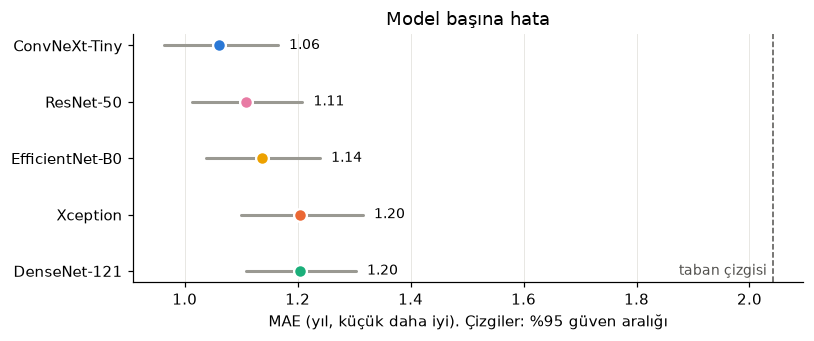

In [14]:
r = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5,3.2))
for i,(_,row) in enumerate(r.iterrows()):
    ax.plot([row['%95 GA alt'],row['%95 GA üst']],[i,i], color='#9a9992', lw=2, solid_capstyle='round')
    ax.scatter(row['MAE (yıl)'], i, s=70, color=COLORS[row.Model], zorder=3, edgecolors='white', linewidths=1.5)
    ax.text(row['%95 GA üst']+.02, i, f"{row['MAE (yıl)']:.2f}", va='center', fontsize=9)
ax.set_yticks(range(len(r))); ax.set_yticklabels(r.Model); ax.grid(axis='y', visible=False)
ax.axvline(base_m['MAE'], color='#52514e', ls='--', lw=1); ax.text(base_m['MAE']-.01, 0, 'taban çizgisi', ha='right', va='center', fontsize=9, color='#52514e')
ax.set(xlabel='MAE (yıl, küçük daha iyi). Çizgiler: %95 güven aralığı', title='Model başına hata')
plt.tight_layout(); plt.show()

### Farkların istatistiksel olarak değerlendirilmesi

Güven aralıklarının çakışması tek başına yeterli bir kanıt değildir. Modeller aynı görüntüleri tahmin ettiği için, görüntü görüntü eşleştirilmiş karşılaştırma yapılır:

- Friedman testi: Beş model arasında genel bir fark var mı?
- En iyi modele karşı Wilcoxon testi (Holm düzeltmeli): Her model en iyi modelden farklı mı?
- Eşleştirilmiş bootstrap: MAE farkının büyüklüğü ve güven aralığının 0'ı içerip içermediği.

In [15]:
AE = pd.DataFrame({k: np.abs(v['oof']-y) for k,v in ALL.items()}).dropna()
if AE.shape[1] >= 3:
    fr = stats.friedmanchisquare(*[AE[c] for c in AE]); print(f'Friedman: χ²={fr.statistic:.2f}, p={fr.pvalue:.4f}')
best = res.Model[0]; rows=[]; rng=np.random.default_rng(SEED)
for m in res.Model[1:]:
    d = (AE[m]-AE[best]).values; p = stats.wilcoxon(AE[m],AE[best]).pvalue
    s = [d[rng.integers(0,len(d),len(d))].mean() for _ in range(5000)]; lo,hi = np.percentile(s,[2.5,97.5])
    rows.append(dict(Model=m, fark=d.mean(), alt=lo, ust=hi, p_ham=p))
cmp = pd.DataFrame(rows).sort_values('p_ham').reset_index(drop=True)
if len(cmp):
    k=len(cmp); cmp['p_Holm']=np.maximum.accumulate([min(1,p*(k-i)) for i,p in enumerate(cmp.p_ham)]); cmp['anlamlı (<.05)']=cmp.p_Holm<.05
print(f'En iyi model: {best}. fark = bu modelin MAE\'si eksi en iyinin MAE\'si')
cmp.round(3)

Friedman: χ²=8.23, p=0.0836
En iyi model: ConvNeXt-Tiny. fark = bu modelin MAE'si eksi en iyinin MAE'si


,Model,fark,alt,ust,p_ham,p_Holm,anlamlı (<.05)
0,DenseNet-121,0.143,0.065,0.224,0.000,0.002,True
1,Xception,0.143,0.061,0.228,0.002,0.006,True
2,EfficientNet-B0,0.076,-0.003,0.156,0.094,0.188,False
3,ResNet-50,0.049,-0.033,0.129,0.271,0.271,False


## 14. Yaş bandına göre hata

Hatalar yaş bandına göre ayrılmıştır. Ayrıca her model için küçük yaşları olduğundan büyük, büyük yaşları olduğundan küçük tahmin etme eğilimi (ortalamaya çekme) ölçülmüştür.

,n,ConvNeXt-Tiny,Xception,DenseNet-121,EfficientNet-B0,ResNet-50
9-11,25,1.09,1.53,1.46,1.30,1.26
12-13,54,1.03,1.07,1.34,1.26,1.09
14-15,62,1.11,1.09,0.99,1.12,1.10
16,50,0.92,0.89,0.97,0.76,0.89
17,56,0.77,1.09,0.96,0.91,0.93
18-19,47,1.52,1.79,1.73,1.61,1.50


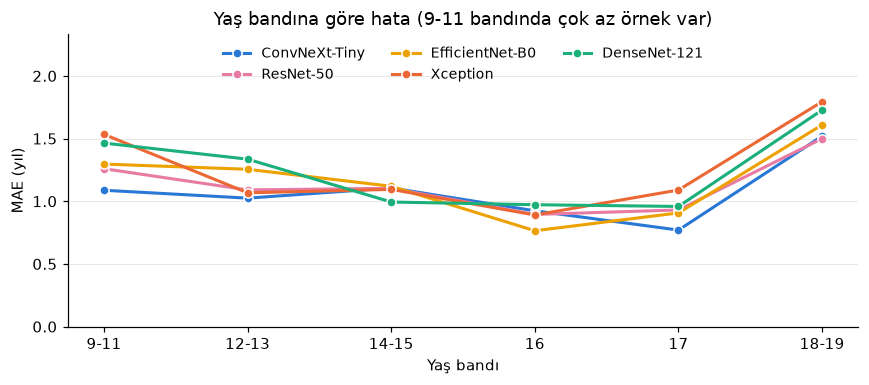

Tahmin = eğim × gerçek yaş + kesişim. Eğim 1 ideal; 1'den küçükse ortalamaya çekme var.


,eğim,kesişim
ConvNeXt-Tiny,0.709,4.389
Xception,0.600,5.925
DenseNet-121,0.618,5.740
EfficientNet-B0,0.651,5.242
ResNet-50,0.674,4.932


In [16]:
order = ['9-11','12-13','14-15','16','17','18-19']
bt = pd.DataFrame({k: pd.Series(np.abs(v['oof']-y)).groupby(bands.values, observed=True).mean() for k,v in ALL.items()}).loc[order]
bt.insert(0,'n',pd.Series(bands.values).value_counts().loc[order].values)
display(bt.round(2))
fig, ax = plt.subplots(figsize=(8,3.6))
for m in res.Model:
    ax.plot(order, bt[m], marker='o', ms=6, lw=2, color=COLORS[m], label=m, markeredgecolor='white')
ax.set(xlabel='Yaş bandı', ylabel='MAE (yıl)', title='Yaş bandına göre hata (9-11 bandında çok az örnek var)'); ax.legend(frameon=False, ncol=3, loc='upper center', fontsize=9)
ax.set_ylim(0, bt[res.Model].values.max()*1.3); ax.grid(axis='x', visible=False); plt.tight_layout(); plt.show()
sig = pd.DataFrame({k: dict(zip(['eğim','kesişim'], np.polyfit(y[~np.isnan(v['oof'])], v['oof'][~np.isnan(v['oof'])], 1))) for k,v in ALL.items()}).T
print('Tahmin = eğim × gerçek yaş + kesişim. Eğim 1 ideal; 1\'den küçükse ortalamaya çekme var.'); sig.round(3)

In [17]:
b = res.Model[0]; o = ALL[b]['oof']
e = pd.DataFrame(dict(name=df.name, age=y, pred=o.round(2), err=(o-y).round(2))).dropna(); e['abs']=e.err.abs()
print(f'{b}: en büyük 10 hata'); display(e.sort_values('abs',ascending=False).head(10).drop(columns='abs'))
print('Hata > 2 yıl olan görüntü sayısı:', (e['abs']>2).sum(), '/', len(e))

ConvNeXt-Tiny: en büyük 10 hata


,name,age,pred,err
172,16 42.jpg,16,12.18,-3.82
256,18 22.jpg,18,14.20,-3.80
47,12 34.jpg,12,15.77,3.77
3,11 1.jpg,11,14.67,3.67
255,18 21.jpg,18,14.39,-3.61
272,18 38.jpg,18,14.41,-3.59
286,19 7.jpg,19,15.45,-3.55
139,16 12.jpg,16,12.51,-3.49
50,12 4.jpg,12,15.17,3.17
2,10.jpg,10,13.16,3.16


Hata > 2 yıl olan görüntü sayısı: 44 / 294


## 15. Literatürle karşılaştırma

| Çalışma | Veri | Model | Değerlendirme | MAE (yıl) |
|---|---|---|---|---|
| Bu çalışma | Zenodo, 294 görüntü, 9-19 yaş | ConvNeXt-Tiny | 5 katlı, tüm görüntüler | 1,06 |
| Bu çalışma | Aynı | ResNet-50 | 5 katlı, tüm görüntüler | 1,11 |
| Frontiers in Radiology 2026 | Zenodo, 296 görüntü | ResNet-50 | Tek test kümesi, 45 görüntü | 0,98 |
| Dental_011 | Zenodo, 295 görüntü | ResNet-18 | Tek test kümesi, 45 görüntü | 0,78 (%95 GA 0,58–1,01) |
| UFPE, Sci. Reports 2024 | 12.827 görüntü, 2,25-96,5 yaş | InceptionV4 | Tek test kümesi | 3,1 |

- Aynı veri setindeki çalışmaların hataları bu çalışmanın sonuçlarına yakındır. Farklar, 45 görüntülük testlerin belirsizliği ve farklı bölme yöntemleri düşünüldüğünde tek başına üstünlük göstermez.
- UFPE çalışmasındaki 3,1 yıllık hata bu çalışmayla doğrudan karşılaştırılamaz: yaş aralığı çok daha geniştir ve yetişkinlerde diş gelişimi tamamlandığı için yaş tahmini zorlaşır.
- Frontiers çalışması RMSE = 1,20 ile R² = 0,95 bildiriyor. Bu veride yaş varyansı yaklaşık 5,9 olduğundan, standart R² tanımıyla RMSE = 1,20 yaklaşık R² = 0,75'e karşılık gelir. Bildirilen R² muhtemelen farklı bir tanım veya hesapla elde edilmiştir; doğrudan kıyaslarken dikkatli olunmalıdır.

## 16. Sonuç ve sınırlılıklar

### Bulgular

1. Beş modelin MAE değeri 1,06–1,20 yıl, taban çizgisinin MAE değeri 2,04 yıldır.
2. ConvNeXt-Tiny ilk sırada. ResNet-50 ve EfficientNet-B0 ile farkı istatistiksel olarak ayırt edilemiyor. DenseNet-121 ve Xception ile eşleştirilmiş testlerde fark anlamlı çıkıyor (Holm düzeltmeli p = 0,002 ve 0,006), ancak genel Friedman testi anlamlı olmadığı ve karşılaştırma en iyi model seçildikten sonra yapıldığı için bu bulgu keşifsel kabul edilmelidir.
3. Sonraki adımlar için ana model ConvNeXt-Tiny, literatür kıyası için ResNet-50. EfficientNet-B0, yaklaşık 7 kat daha az parametreyle yakın sonuç veriyor; hafif model gerekirse iyi bir aday.
4. Tüm modellerde en büyük hata bu banttadır (1,50–1,79 yıl). Olası bir sebep, diş gelişiminin bu yaşlarda tamamlanmaya yaklaşması ve görüntüdeki yaş işaretlerinin azalmasıdır; bu mevcut deneyle kanıtlanmış değildir.
5. Eğim 0,60–0,71 arasındadır; modeller küçük yaşları olduğundan büyük, büyük yaşları olduğundan küçük tahmin etme eğilimindedir. Bu sistematik hata, projede ölçülmek istenen hata kaynaklarından biridir.

### Sınırlılıklar

- Örneklem küçük (9-11 yaş bandında 25 görüntü) ve yaş aralığı dardır.
- Görüntülerin büyük kısmı yaklaşık 400×187 piksel; ince yapılar kaybolmuş olabilir.
- Aynı kişiye ait farklı görüntüler ayıklanamadığından sonuçlar olduğundan iyi görünebilir.
- Yaşlar tam yıl olduğundan, modeller kusursuz olsa bile yaklaşık 0,25 yıllık bir hata kalır (yıl içinde eşit dağılım varsayımıyla).
- Tüm modeller tek bir ayarla ve tek rastgele başlangıçla eğitildi. Her model için ayrı ayar yapılsa sıralama değişebilir.
- Eğitim ve tahmin süreleri, çalışma kesintiye uğradığı ve bilgisayarda başka işlemler de yürütüldüğü için yalnızca yaklaşık değerlerdir (örneğin Xception 1. kat 10,4 dk).
- Sonuçlar başka bir popülasyonda ya da cihazda sınanmadı. Bu sonuçlar adli kullanım için yeterli değildir.

### Sonraki adımlar

1. UFPE verisine erişim sağlamak ve aynı karşılaştırmayı bu veride tekrarlamak.
2. Hatanın kaynağını anlamak için modellerin dişin hangi bölgelerine baktığını incelemek.
3. El yapımı ölçütleri (Cameriere, Kvaal, pulpa-diş oranı) eklemeden önce, bunların gerektirdiği diş sınırlarının nasıl elde edileceğine karar vermek.